Urządzenie: cpu
Ziarno losowania: 42
Liczba próbek treningowych: 4000
Liczba próbek testowych: 800
Liczba epok: 30
Rozmiar partii: 128

========== SPRAWDZENIE GENERATORA ==========
Pozycje znaczników (numeracja od 1): [10 18]
Pozycje wskazywanych wartości (numeracja od 1): [ 2 10]
Wskazywane wartości: [0.43887845 0.45038593]
Pierwsza wartość: 0.43887845
Druga wartość: 0.45038593
Prawidłowa suma: 0.8892643451690674

Cała sekwencja:
Krok  1: wartość=0.7740, znacznik=0
Krok  2: wartość=0.4389, znacznik=0
Krok  3: wartość=0.8586, znacznik=0
Krok  4: wartość=0.6974, znacznik=0
Krok  5: wartość=0.0942, znacznik=0
Krok  6: wartość=0.9756, znacznik=0
Krok  7: wartość=0.7611, znacznik=0
Krok  8: wartość=0.7861, znacznik=0
Krok  9: wartość=0.1281, znacznik=0
Krok 10: wartość=0.4504, znacznik=1
Krok 11: wartość=0.3708, znacznik=0
Krok 12: wartość=0.9268, znacznik=0
Krok 13: wartość=0.6439, znacznik=0
Krok 14: wartość=0.8228, znacznik=0
Krok 15: wartość=0.4434, znacznik=0
Krok 16: wartość=0.2272, 

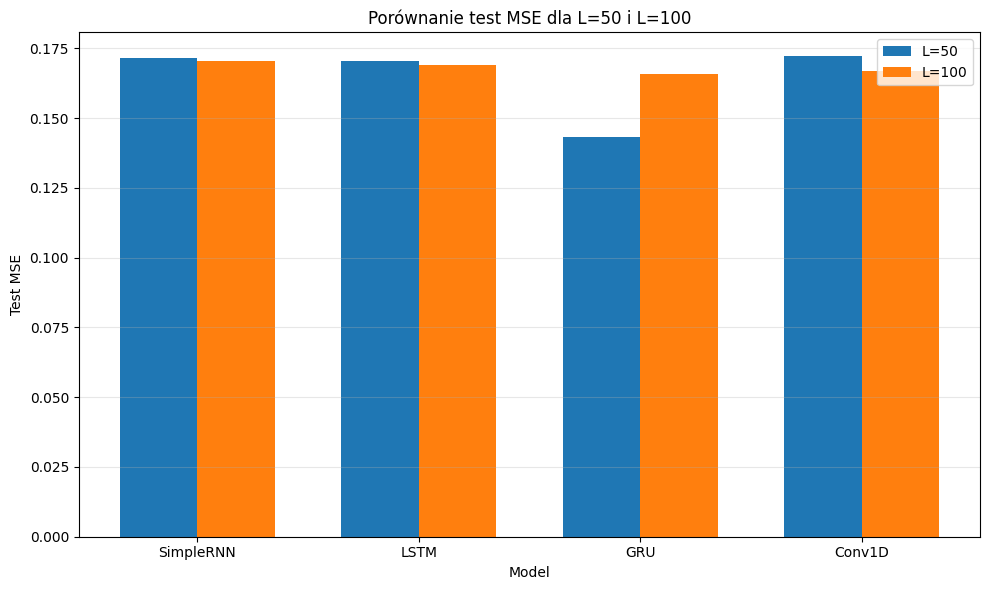



DODATKOWY EKSPERYMENT: SIMPLE RNN


In [ ]:

import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

N_TRAIN = 4000
N_TEST = 800
EPOCHS = 30
BATCH_SIZE = 128
LEARNING_RATE = 0.005

HIDDEN = 32
CHANNELS = 32
DELAY = 8

print("Urządzenie:", DEVICE)
print("Ziarno losowania:", SEED)
print("Liczba próbek treningowych:", N_TRAIN)
print("Liczba próbek testowych:", N_TEST)
print("Liczba epok:", EPOCHS)
print("Rozmiar partii:", BATCH_SIZE)



def gen(N, L, rng=None):
    """
    Generuje sekwencje o dwóch kanałach:
    kanał 1 - losowe wartości z przedziału [0,1],
    kanał 2 - znaczniki 0 lub 1.

    Znacznik w kroku t wskazuje wartość z kroku t-8.
    Pozycje znaczników są różne i należą do zakresu 9...L.
    """

    if rng is None:
        rng = np.random.default_rng()

    val = rng.uniform(0, 1, (N, L, 1)).astype(np.float32)

    mark = np.zeros((N, L, 1), dtype=np.float32)

    y = np.zeros((N, 1), dtype=np.float32)

    for i in range(N):


        positions = rng.choice(
            np.arange(DELAY, L),
            size=2,
            replace=False
        )

        mark[i, positions, 0] = 1.0


        source_positions = positions - DELAY

        y[i, 0] = val[i, source_positions, 0].sum()

    x = np.concatenate([val, mark], axis=2)

    return (
        torch.tensor(x, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )



print("\n========== SPRAWDZENIE GENERATORA ==========")

X_example, Y_example = gen(
    1,
    20,
    np.random.default_rng(SEED)
)

values = X_example[0, :, 0].numpy()
markers = X_example[0, :, 1].numpy()

marker_positions = np.where(markers == 1)[0]
source_positions = marker_positions - DELAY

print("Pozycje znaczników (numeracja od 1):",
      marker_positions + 1)

print("Pozycje wskazywanych wartości (numeracja od 1):",
      source_positions + 1)

print("Wskazywane wartości:",
      values[source_positions])

print("Pierwsza wartość:",
      values[source_positions[0]])

print("Druga wartość:",
      values[source_positions[1]])

print("Prawidłowa suma:",
      float(Y_example[0, 0]))

print("\nCała sekwencja:")
for i in range(20):
    print(
        f"Krok {i+1:2d}: "
        f"wartość={values[i]:.4f}, "
        f"znacznik={int(markers[i])}"
    )



class RNNNet(nn.Module):

    def __init__(self, typ, hidden=32):

        super().__init__()

        self.rnn = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }[typ](
            input_size=2,
            hidden_size=hidden,
            batch_first=True
        )

        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):

        out, _ = self.rnn(x)


        return self.fc(out[:, -1, :])


class ConvNet(nn.Module):

    def __init__(self, channels=32, dilations=(1, 2, 4)):

        super().__init__()

        layers = []
        in_channels = 2

        for dilation in dilations:

            layers.append(
                nn.Conv1d(
                    in_channels,
                    channels,
                    kernel_size=3,
                    stride=1,
                    padding=dilation,
                    dilation=dilation
                )
            )

            layers.append(nn.ReLU())

            in_channels = channels

        self.net = nn.Sequential(*layers)

        self.fc = nn.Linear(channels, 1)

    def forward(self, x):


        h = self.net(x.transpose(1, 2))


        h = h.mean(dim=2)

        return self.fc(h)


def licz_parametry(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )



def trenuj(model, Xtr, Ytr, Xte, Yte):

    model = model.to(DEVICE)

    Xtr = Xtr.to(DEVICE)
    Ytr = Ytr.to(DEVICE)
    Xte = Xte.to(DEVICE)
    Yte = Yte.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.MSELoss()

    N = len(Xtr)


    if DEVICE == 'cuda':
        torch.cuda.synchronize()

    start = time.time()

    for epoch in range(EPOCHS):

        model.train()

        permutation = torch.randperm(N, device=DEVICE)

        for i in range(0, N, BATCH_SIZE):

            indices = permutation[i:i+BATCH_SIZE]

            xb = Xtr[indices]
            yb = Ytr[indices]

            optimizer.zero_grad()

            predictions = model(xb)

            loss = criterion(predictions, yb)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )

            optimizer.step()

    if DEVICE == 'cuda':
        torch.cuda.synchronize()

    training_time = time.time() - start


    model.eval()

    with torch.no_grad():

        predictions = model(Xte)

        test_mse = criterion(
            predictions,
            Yte
        ).item()

    return {
        'model': model,
        'mse': test_mse,
        'czas': training_time,
        'params': licz_parametry(model)
    }



def baseline_mse(Ytr, Yte):


    prediction = Ytr.mean()

    mse = torch.mean(
        (Yte - prediction) ** 2
    ).item()

    return mse



wyniki = {}
zbiory = {}
wytrenowane_modele = {}

for L in [50, 100]:

    print("\n")
    print("=" * 65)
    print(f"PORÓWNANIE MODELI DLA L={L}")
    print("=" * 65)



    rng_train = np.random.default_rng(SEED + L)
    rng_test = np.random.default_rng(SEED + L + 1000)

    Xtr, Ytr = gen(N_TRAIN, L, rng_train)
    Xte, Yte = gen(N_TEST, L, rng_test)

    zbiory[L] = (Xtr, Ytr, Xte, Yte)

    base = baseline_mse(Ytr, Yte)

    print(f"Baseline MSE: {base:.6f}")

    wyniki[L] = {}


    konfiguracje = {
        'SimpleRNN': lambda: RNNNet('RNN', HIDDEN),
        'LSTM': lambda: RNNNet('LSTM', HIDDEN),
        'GRU': lambda: RNNNet('GRU', HIDDEN),
        'Conv1D': lambda: ConvNet(
            CHANNELS,
            dilations=(1, 2, 4)
        )
    }

    for nazwa, konstruktor in konfiguracje.items():

        print(f"\nTrening modelu {nazwa}...")


        torch.manual_seed(SEED + L + len(wyniki[L]))

        model = konstruktor()

        wynik = trenuj(
            model,
            Xtr,
            Ytr,
            Xte,
            Yte
        )

        wyniki[L][nazwa] = wynik
        wytrenowane_modele[(L, nazwa)] = wynik['model']

        print(
            f"{nazwa:12s} | "
            f"MSE={wynik['mse']:.6f} | "
            f"Czas={wynik['czas']:.2f} s | "
            f"Parametry={wynik['params']}"
        )

    wyniki[L]['Baseline'] = {
        'mse': base,
        'czas': 0,
        'params': 0
    }



wiersze = []

for L in [50, 100]:

    for nazwa, wynik in wyniki[L].items():

        wiersze.append({
            'Długość L': L,
            'Model': nazwa,
            'Test MSE': wynik['mse'],
            'Czas treningu [s]': wynik['czas'],
            'Liczba parametrów': wynik['params']
        })

tabela = pd.DataFrame(wiersze)

print("\n========== TABELA WYNIKÓW ==========")

print(
    tabela.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)



nazwy_modeli = [
    'SimpleRNN',
    'LSTM',
    'GRU',
    'Conv1D'
]

x = np.arange(len(nazwy_modeli))
width = 0.35

mse50 = [
    wyniki[50][n]['mse']
    for n in nazwy_modeli
]

mse100 = [
    wyniki[100][n]['mse']
    for n in nazwy_modeli
]

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    mse50,
    width,
    label='L=50'
)

plt.bar(
    x + width/2,
    mse100,
    width,
    label='L=100'
)

plt.xticks(x, nazwy_modeli)

plt.ylabel('Test MSE')
plt.xlabel('Model')

plt.title('Porównanie test MSE dla L=50 i L=100')

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()




print("\n")
print("=" * 65)
print("DODATKOWY EKSPERYMENT: SIMPLE RNN")
print("=" * 65)

Xtr, Ytr, Xte, Yte = zbiory[100]

torch.manual_seed(SEED + 500)

rnn32 = trenuj(
    RNNNet('RNN', hidden=32),
    Xtr, Ytr, Xte, Yte
)

torch.manual_seed(SEED + 501)

rnn64 = trenuj(
    RNNNet('RNN', hidden=64),
    Xtr, Ytr, Xte, Yte
)

print("\nWyniki SimpleRNN:")

print(
    f"Hidden=32 | MSE={rnn32['mse']:.6f} | "
    f"Czas={rnn32['czas']:.2f}s | "
    f"Parametry={rnn32['params']}"
)

print(
    f"Hidden=64 | MSE={rnn64['mse']:.6f} | "
    f"Czas={rnn64['czas']:.2f}s | "
    f"Parametry={rnn64['params']}"
)




print("\n")
print("=" * 65)
print("DODATKOWY EKSPERYMENT: CONV1D")
print("=" * 65)


torch.manual_seed(SEED + 600)

conv_dilated = trenuj(
    ConvNet(
        channels=CHANNELS,
        dilations=(1, 2, 4)
    ),
    Xtr, Ytr, Xte, Yte
)


torch.manual_seed(SEED + 601)

conv_normal = trenuj(
    ConvNet(
        channels=CHANNELS,
        dilations=(1, 1, 1)
    ),
    Xtr, Ytr, Xte, Yte
)

print("\nWyniki Conv1D:")

print(
    f"Dylatacje [1,2,4] | "
    f"MSE={conv_dilated['mse']:.6f} | "
    f"Czas={conv_dilated['czas']:.2f}s | "
    f"Parametry={conv_dilated['params']}"
)

print(
    f"Dylatacje [1,1,1] | "
    f"MSE={conv_normal['mse']:.6f} | "
    f"Czas={conv_normal['czas']:.2f}s | "
    f"Parametry={conv_normal['params']}"
)



def pole_recepcyjne(dilations, kernel_size=3):

    receptive_field = 1

    for dilation in dilations:

        receptive_field += (
            kernel_size - 1
        ) * dilation

    return receptive_field


rf_dilated = pole_recepcyjne([1, 2, 4])
rf_normal = pole_recepcyjne([1, 1, 1])

print("\n========== POLE RECEPCYJNE ==========")

print(
    "Conv1D [1,2,4]:",
    rf_dilated,
    "pozycji"
)

print(
    "Conv1D [1,1,1]:",
    rf_normal,
    "pozycji"
)

print(
    "Odległość między znacznikiem a wskazywaną wartością:",
    DELAY,
    "kroków"
)

print(
    "Conv1D [1,2,4] może objąć obie pozycje:",
    rf_dilated >= DELAY + 1
)

print(
    "Conv1D [1,1,1] może objąć obie pozycje:",
    rf_normal >= DELAY + 1
)




dodatkowe = pd.DataFrame([
    {
        'Model': 'SimpleRNN hidden=32',
        'Test MSE': rnn32['mse'],
        'Czas [s]': rnn32['czas'],
        'Parametry': rnn32['params']
    },
    {
        'Model': 'SimpleRNN hidden=64',
        'Test MSE': rnn64['mse'],
        'Czas [s]': rnn64['czas'],
        'Parametry': rnn64['params']
    },
    {
        'Model': 'Conv1D dilation=[1,2,4]',
        'Test MSE': conv_dilated['mse'],
        'Czas [s]': conv_dilated['czas'],
        'Parametry': conv_dilated['params']
    },
    {
        'Model': 'Conv1D dilation=[1,1,1]',
        'Test MSE': conv_normal['mse'],
        'Czas [s]': conv_normal['czas'],
        'Parametry': conv_normal['params']
    }
])

print("\n========== DODATKOWE WYNIKI ==========")

print(
    dodatkowe.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)



print("\n")
print("=" * 65)
print("PRZYKŁAD TESTOWY Z DUŻYM BŁĘDEM")
print("=" * 65)


wybrany_model = max(
    nazwy_modeli,
    key=lambda n: wyniki[100][n]['mse']
)

model = wytrenowane_modele[(100, wybrany_model)]

model.eval()

Xtr, Ytr, Xte, Yte = zbiory[100]

with torch.no_grad():

    predictions = model(Xte.to(DEVICE)).cpu().numpy()

targets = Yte.numpy()

errors = (predictions[:, 0] - targets[:, 0]) ** 2


idx = int(np.argmax(errors))

sample = Xte[idx].numpy()

values = sample[:, 0]
markers = sample[:, 1]

marker_positions = np.where(markers == 1)[0]
source_positions = marker_positions - DELAY

correct_sum = float(targets[idx, 0])
predicted_sum = float(predictions[idx, 0])

print("Wybrany model:", wybrany_model)
print("Indeks próbki:", idx)

print(
    "Pozycje znaczników:",
    marker_positions + 1
)

print(
    "Pozycje wskazywanych wartości:",
    source_positions + 1
)

print(
    "Pierwsza wskazywana wartość:",
    values[source_positions[0]]
)

print(
    "Druga wskazywana wartość:",
    values[source_positions[1]]
)

print("Prawidłowa suma:", correct_sum)
print("Predykcja modelu:", predicted_sum)
print("Błąd kwadratowy:", errors[idx])




print("\n")
print("=" * 65)
print("PODSUMOWANIE EKSPERYMENTU")
print("=" * 65)

for L in [50, 100]:

    print(f"\nDługość sekwencji L={L}")

    baseline = wyniki[L]['Baseline']['mse']

    print(f"Baseline MSE: {baseline:.6f}")

    for nazwa in nazwy_modeli:

        mse = wyniki[L][nazwa]['mse']

        if mse < baseline:
            print(
                f"{nazwa}: wynik lepszy od baseline "
                f"({mse:.6f})"
            )
        else:
            print(
                f"{nazwa}: wynik nie jest lepszy od baseline "
                f"({mse:.6f})"
            )

print("\nWpływ zwiększenia stanu ukrytego:")

print(
    "Zmiana MSE:",
    round(rnn64['mse'] - rnn32['mse'], 6)
)

print(
    "Zmiana liczby parametrów:",
    rnn64['params'] - rnn32['params']
)

print(
    "Zmiana czasu:",
    round(rnn64['czas'] - rnn32['czas'], 3),
    "s"
)

print("\nWpływ dylatacji Conv1D:")

print(
    "Zmiana MSE:",
    round(
        conv_normal['mse'] - conv_dilated['mse'],
        6
    )
)

print("\nKoniec eksperymentu.")
